# Feature Engineering – Betrugserkennung bei Strom und Gas
**Team 5 (Roland, Leo, Tobias)** · Meilenstein 3

In der EDA haben wir pro Kunde nur einfache Kennzahlen gebildet. Hier bauen wir aus den Rechnungen **neue Features**, die zu den Mustern aus der EDA passen.

Daten: Rechnungen aus `data/train/` + `data/fd_cleaned.csv` → neu: `data/fd_features.csv`

| # | Schritt | Idee aus der EDA |
|---|---|---|
| 1 | Setup und Daten laden | |
| 2 | Rechnungen bereinigen | wie in der EDA |
| 3 | Features v1: Verbrauch pro Monat, Ablese-Bemerkungen | Rechnungen sind unterschiedlich lang |
| 4 | Features v2: Sprünge, Trend, Schwankung | Betrüger haben unruhigen Verbrauch |
| 5 | Alles zusammenführen | |
| 6 | Kurzer Check: Haben die neuen Features ein Signal? | |
| 7 | Speichern | |

## 1 · Setup und Daten laden

In [5]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("data")
TRAIN_DIR = DATA_DIR / "train"

In [6]:

if not (TRAIN_DIR / "invoice_train.csv").exists():
    with zipfile.ZipFile(DATA_DIR / "train.zip") as zf:
        zf.extractall(TRAIN_DIR)

df_invoice = pd.read_csv(TRAIN_DIR / "invoice_train.csv", dtype={"counter_statue": str})
df_cleaned = pd.read_csv(DATA_DIR / "fd_cleaned.csv")
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")

print("Rechnungen:", df_invoice.shape)
print("Kunden:    ", df_cleaned.shape)

Rechnungen: (4476749, 16)
Kunden:     (135493, 20)


## 2 · Rechnungen bereinigen

In [7]:
df_invoice = df_invoice.drop_duplicates().reset_index(drop=True)
df_invoice["invoice_date"] = pd.to_datetime(df_invoice["invoice_date"], format="%Y-%m-%d")

stufen = ["consommation_level_1", "consommation_level_2", "consommation_level_3", "consommation_level_4"]
df_invoice["consumption"] = df_invoice[stufen].sum(axis=1)

df_invoice.shape

(4476738, 17)

## 3 · Features v1
### 3.1 Verbrauch pro Monat
Eine Rechnung geht meistens über 4 Monate, manchmal aber über 1, 2 oder 8. Damit Rechnungen vergleichbar sind, teilen wir den Verbrauch durch die Anzahl der Monate.

Vorher fangen wir die unmöglichen Werte ab: `months_number` von 0 (durch 0 teilen geht nicht) und über 24 (bis über 600.000 Monate, siehe EDA) setzen wir auf `NaN`.

In [8]:
monate = df_invoice["months_number"].copy()
monate[(monate < 1) | (monate > 24)] = np.nan

df_invoice["cons_per_month"] = df_invoice["consumption"] / monate

print(f"Rechnungen ohne gültige Monate: {monate.isna().sum():,} ({monate.isna().mean():.2%})")
df_invoice.groupby("counter_type")["cons_per_month"].describe().round(1)

Rechnungen ohne gültige Monate: 3,530 (0.08%)


,count,mean,std,min,25%,50%,75%,max
counter_type,,,,,,,,
ELEC,3077150.0,228.9,885.9,0.0,56.2,112.5,193.8,499836.5
GAZ,1396058.0,63.7,492.4,0.0,6.2,21.0,41.5,499955.0


In [9]:
# Pro Kunde: Median und Schwankung des Monatsverbrauchs, getrennt nach Strom und Gas
df_monat_strom = df_invoice[df_invoice["counter_type"] == "ELEC"].groupby("client_id")["cons_per_month"].agg(["median", "std"])
df_monat_strom.columns = ["month_median_elec", "month_std_elec"]

df_monat_gas = df_invoice[df_invoice["counter_type"] == "GAZ"].groupby("client_id")["cons_per_month"].agg(["median", "std"])
df_monat_gas.columns = ["month_median_gaz", "month_std_gaz"]

df_monat_strom.head()

,month_median_elec,month_std_elec
client_id,,
train_Client_0,54.2500,84.545640
train_Client_1,128.5000,24.105605
train_Client_10,115.5625,45.304153
train_Client_100,0.0000,0.901753
train_Client_1000,192.5000,150.969514


### 3.2 Bemerkungen des Ablesers
`reading_remarque` hat drei große Codes: 6, 8 und 9 (EDA, 7.4). Wir zählen pro Kunde, wie oft welcher Code vorkommt (als Anteil).

In [10]:
df_invoice["remarque_6"] = (df_invoice["reading_remarque"] == 6).astype(int)
df_invoice["remarque_8"] = (df_invoice["reading_remarque"] == 8).astype(int)
df_invoice["remarque_9"] = (df_invoice["reading_remarque"] == 9).astype(int)

df_remarque = df_invoice.groupby("client_id")[["remarque_6", "remarque_8", "remarque_9"]].mean()
df_remarque.columns = ["share_remarque_6", "share_remarque_8", "share_remarque_9"]

df_remarque.describe().round(3)

,share_remarque_6,share_remarque_8,share_remarque_9
count,135493.000,135493.000,135493.000
mean,0.480,0.162,0.356
std,0.294,0.159,0.304
min,0.000,0.000,0.000
25%,0.273,0.000,0.122
50%,0.500,0.146,0.280
75%,0.667,0.250,0.500
max,1.000,1.000,1.000


## 4 · Features v2: Sprünge, Trend, Schwankung
In der EDA hatten Betrüger einen viel **unruhigeren** Verbrauch. Wer manchmal manipuliert und manchmal nicht, hat plötzliche Einbrüche und Sprünge.

### 4.1 Sprünge zwischen zwei Rechnungen
Wir sortieren die Rechnungen pro Zähler nach Datum und schauen, wie stark sich der Monatsverbrauch von einer Rechnung zur nächsten ändert. Wir rechnen pro **Zähler** (`counter_number`), damit ein Zählertausch keinen falschen Sprung erzeugt.

In [11]:
df_invoice = df_invoice.sort_values(["client_id", "counter_number", "counter_type", "invoice_date"])

# Änderung zur vorherigen Rechnung desselben Zählers
df_invoice["change"] = df_invoice.groupby(["client_id", "counter_number", "counter_type"])["cons_per_month"].diff()
df_invoice["abs_change"] = df_invoice["change"].abs()

df_spruenge = df_invoice.groupby("client_id").agg(
    max_drop=("change", "min"),         # größter Rückgang (negative Zahl)
    max_rise=("change", "max"),         # größter Anstieg
    mean_abs_change=("abs_change", "mean"),
)
# Rückgang als positive Zahl, das ist leichter zu lesen.
# Gab es nur Anstiege (bzw. nur Rückgänge), setzen wir den anderen Wert auf 0.
df_spruenge["max_drop"] = (-df_spruenge["max_drop"]).clip(lower=0)
df_spruenge["max_rise"] = df_spruenge["max_rise"].clip(lower=0)

df_spruenge.describe().round(1)

,max_drop,max_rise,mean_abs_change
count,130080.0,130080.0,130080.0
mean,344.3,343.6,93.1
std,2269.3,2647.2,398.8
min,-0.0,0.0,0.0
25%,65.8,66.8,22.3
50%,141.6,140.5,40.0
75%,280.2,277.8,77.6
max,498754.0,499836.5,46779.0


### 4.2 Trend: Verbrauch in den letzten 2 Jahren gegenüber vorher
Wenn jemand anfängt zu manipulieren, sinkt sein Verbrauch. Wir vergleichen pro Kunde den mittleren Monatsverbrauch in den **letzten 2 Jahren seiner Rechnungen** mit der Zeit davor.

* Wert unter 1: Verbrauch ist gesunken
* Wert über 1: Verbrauch ist gestiegen

In [12]:
# Letzte Rechnung pro Kunde an jede Rechnung schreiben
letzte_rechnung = df_invoice.groupby("client_id")["invoice_date"].max()
df_invoice["last_invoice"] = df_invoice["client_id"].map(letzte_rechnung)
df_invoice["recent"] = df_invoice["invoice_date"] >= df_invoice["last_invoice"] - pd.Timedelta(days=730)

verbrauch_neu = df_invoice[df_invoice["recent"]].groupby("client_id")["cons_per_month"].mean()
verbrauch_alt = df_invoice[~df_invoice["recent"]].groupby("client_id")["cons_per_month"].mean()

df_trend = pd.DataFrame({"cons_recent": verbrauch_neu, "cons_before": verbrauch_alt})
# +1, damit wir bei Verbrauch 0 nicht durch 0 teilen
df_trend["trend_ratio"] = (df_trend["cons_recent"] + 1) / (df_trend["cons_before"] + 1)

df_trend["trend_ratio"].describe().round(2)

count    110981.00
mean          2.80
std          41.39
min           0.00
25%           0.66
50%           0.97
75%           1.33
max        7220.10
Name: trend_ratio, dtype: float64

### 4.3 Schwankung im Verhältnis zum Verbrauch
Eine Standardabweichung von 300 ist bei einem Verbrauch von 3.000 wenig, bei 300 aber viel. Deshalb teilen wir die Schwankung durch den Mittelwert (**Variationskoeffizient**). Das rechnen wir unten direkt in der fertigen Tabelle aus.

## 5 · Alles zusammenführen
Wir hängen alle neuen Tabellen per Left Join an `fd_cleaned.csv`, wie in der EDA.

In [13]:
df_features = df_cleaned.copy()

for tabelle in [df_monat_strom, df_monat_gas, df_remarque, df_spruenge, df_trend[["trend_ratio"]]]:
    df_features = df_features.merge(tabelle, on="client_id", how="left")

# Variationskoeffizient (+1, damit wir nicht durch 0 teilen)
df_features["cv_elec"] = df_features["cons_std_elec"] / (df_features["cons_mean_elec"] + 1)
df_features["cv_gaz"] = df_features["cons_std_gaz"] / (df_features["cons_mean_gaz"] + 1)

print("Zeilen:", df_features.shape)
df_features.isna().sum()[df_features.isna().sum() > 0]

Zeilen: (135493, 33)


month_median_elec      812
month_std_elec        5804
month_median_gaz     73474
month_std_gaz        75120
max_drop              5413
max_rise              5413
mean_abs_change       5413
trend_ratio          24512
dtype: int64

**Was fällt auf?**
* Weiterhin eine Zeile pro Kunde.
* Lücken gibt es, wenn ein Kunde kein Gas hat, nur eine Rechnung pro Zähler hat (dann gibt es keinen Sprung) oder keine Rechnungen älter als 2 Jahre (dann gibt es keinen Trend).

**Entscheidung:**
* `trend_ratio` füllen wir mit 1 (= keine Veränderung).
* Alle anderen Lücken füllen wir mit 0 (kein Verbrauch, keine Schwankung, kein Sprung).

In [14]:
df_features["trend_ratio"] = df_features["trend_ratio"].fillna(1)
df_features = df_features.fillna(0)

print("Fehlende Werte:", df_features.isna().sum().sum())

Fehlende Werte: 0


## 6 · Kurzer Check: Haben die neuen Features ein Signal?
Nur im **Train-Teil**, wie in der EDA. Wir schauen auf die Spearman-Korrelation mit `target` und auf die Betrugsquote für den größten Rückgang.

In [15]:
train_ids = df_split.loc[df_split["split"] == "train", "client_id"]
df_check = df_features[df_features["client_id"].isin(train_ids)].copy()

neue_spalten = ["month_median_elec", "month_std_elec", "month_median_gaz", "month_std_gaz",
                "share_remarque_6", "share_remarque_8", "share_remarque_9",
                "max_drop", "max_rise", "mean_abs_change", "trend_ratio", "cv_elec", "cv_gaz"]

korr = df_check[neue_spalten + ["target"]].corr(method="spearman")["target"].drop("target")
korr.sort_values(ascending=False).round(3)

max_drop             0.146
max_rise             0.142
month_std_elec       0.136
mean_abs_change      0.094
cv_elec              0.091
share_remarque_8     0.085
month_std_gaz        0.073
month_median_gaz     0.070
cv_gaz               0.063
month_median_elec    0.055
share_remarque_9     0.026
trend_ratio          0.021
share_remarque_6    -0.029
Name: target, dtype: float64

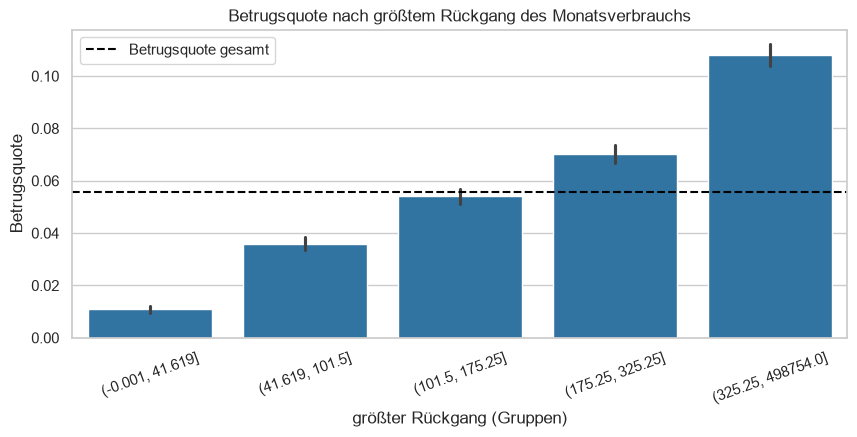

,count,mean
max_drop_gruppe,,
"(-0.001, 41.619]",21679,0.011
"(41.619, 101.5]",21715,0.036
"(101.5, 175.25]",21645,0.054
"(175.25, 325.25]",21684,0.070
"(325.25, 498754.0]",21671,0.108


In [16]:
# Betrugsquote nach größtem Rückgang (5 gleich große Gruppen)
df_check["max_drop_gruppe"] = pd.qcut(df_check["max_drop"], q=5, duplicates="drop")

plt.figure(figsize=(10, 4))
sns.barplot(data=df_check, x="max_drop_gruppe", y="target", color="tab:blue")
plt.axhline(df_check["target"].mean(), color="black", linestyle="--", label="Betrugsquote gesamt")
plt.title("Betrugsquote nach größtem Rückgang des Monatsverbrauchs")
plt.xlabel("größter Rückgang (Gruppen)")
plt.ylabel("Betrugsquote")
plt.xticks(rotation=20)
plt.legend()
plt.show()

df_check.groupby("max_drop_gruppe", observed=True)["target"].agg(["count", "mean"]).round(3)

**Was fällt auf?**
* Der **größte Rückgang** (`max_drop`) ist das stärkste neue Feature (Spearman 0,15, zum Vergleich `n_counters`: 0,18). In der Gruppe mit den kleinsten Rückgängen gibt es 1 % Betrug, in der Gruppe mit den größten 11 %.
* Auch die Schwankung des Monatsverbrauchs (`month_std_elec`) und der größte Anstieg hängen mit Betrug zusammen. Das passt zur EDA: Betrüger haben einen unruhigen Verbrauch.
* Der **Trend** (`trend_ratio`) hat fast kein Signal (0,02). Unsere Idee "der Verbrauch sinkt am Ende" bestätigt sich also nicht.
* `share_remarque_8` hat ein kleines Signal (0,09). Was Code 8 bedeutet, wissen wir nicht.

## 7 · Speichern
`07_modelle.ipynb` baut auf dieser Datei auf. Sie liegt wie `fd_cleaned.csv` nicht auf GitHub.

In [17]:
print(f"Zeilen: {df_features.shape[0]:,}   Spalten: {df_features.shape[1]}")

df_features.to_csv(DATA_DIR / "fd_features.csv", index=False)
print("Gespeichert: data/fd_features.csv")

Zeilen: 135,493   Spalten: 33
Gespeichert: data/fd_features.csv


## Fazit
* `fd_features.csv` hat 33 Spalten: die 20 aus `fd_cleaned.csv` und 13 neue.
* Neu: Monatsverbrauch (Median und Schwankung), Anteile der Ablese-Bemerkungen, größter Rückgang und Anstieg, mittlere Änderung, Trend und Variationskoeffizient.
* Ob die neuen Features dem Modell wirklich helfen, sehen wir in `07_modelle.ipynb`.